In [2]:
#libraries
%pip install econml scikit-learn pandas numpy matplotlib joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 17.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [econml]2m1/2 [econml]
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path

for path in Path("/kaggle/input").rglob("*"):
    print(path)

/kaggle/input/datasets
/kaggle/input/datasets/narupatil8839
/kaggle/input/datasets/narupatil8839/transactions
/kaggle/input/datasets/narupatil8839/promotions
/kaggle/input/datasets/narupatil8839/transactions/transactions_clean.csv
/kaggle/input/datasets/narupatil8839/promotions/promotions_clean.csv


In [4]:
from pathlib import Path
import pandas as pd

TRANSACTIONS_PATH = Path(
    "/kaggle/input/datasets/narupatil8839/transactions/transactions_clean.csv"
)

PROMOTIONS_PATH = Path(
    "/kaggle/input/datasets/narupatil8839/promotions/promotions_clean.csv"
)

transactions = pd.read_csv(TRANSACTIONS_PATH)
promotions = pd.read_csv(PROMOTIONS_PATH)

print("Transactions shape:", transactions.shape)
print("Promotions shape:", promotions.shape)

display(transactions.head())
display(promotions.head())

Transactions shape: (2595732, 12)
Promotions shape: (36786524, 5)


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
0,26190,286,70,0,A
1,26190,288,70,0,A
2,26190,289,70,0,A
3,26190,292,70,0,A
4,26190,293,70,0,A


In [5]:
#Inspect columns before defining the casual variables
print("TRANSACTIONS SAMPLE")
display(transactions.head())

print("PROMOTIONS SAMPLE")
display(promotions.head())

print("\nTransaction data types:")
display(transactions.dtypes.to_frame("data_type"))

print("\nPromotion data types:")
display(promotions.dtypes.to_frame("data_type"))

TRANSACTIONS SAMPLE


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


PROMOTIONS SAMPLE


,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
0,26190,286,70,0,A
1,26190,288,70,0,A
2,26190,289,70,0,A
3,26190,292,70,0,A
4,26190,293,70,0,A



Transaction data types:


,data_type
household_key,int64
BASKET_ID,int64
DAY,int64
PRODUCT_ID,int64
QUANTITY,int64
SALES_VALUE,float64
STORE_ID,int64
RETAIL_DISC,float64
TRANS_TIME,int64
WEEK_NO,int64



Promotion data types:


,data_type
PRODUCT_ID,int64
STORE_ID,int64
WEEK_NO,int64
display,object
mailer,object


In [6]:
#Identify candidate treatment and outcome columns
def find_candidates(df, keywords):
    return [
        col for col in df.columns
        if any(keyword in col.lower() for keyword in keywords)
    ]

print("Possible outcome columns:")
print(find_candidates(
    transactions,
    ["sales", "quantity", "spend", "revenue", "amount", "units"]
))

print("\nPossible treatment columns:")
print(find_candidates(
    promotions,
    ["price", "discount", "promo", "promotion", "treatment", "exposure"]
))

print("\nPossible join keys:")
print("Transactions:", find_candidates(
    transactions, ["product_id", "household_key", "store_id", "week", "day"]
))
print("Promotions:", find_candidates(
    promotions, ["product_id", "store_id", "week", "day", "campaign"]
))

Possible outcome columns:
['QUANTITY', 'SALES_VALUE']

Possible treatment columns:
[]

Possible join keys:
Transactions: ['household_key', 'DAY', 'PRODUCT_ID', 'STORE_ID', 'WEEK_NO']
Promotions: ['PRODUCT_ID', 'STORE_ID', 'WEEK_NO']


In [7]:
#Inspect promotion values and duplicate keys
promo_keys = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]

print("Promotion missing values:")
display(promotions.isnull().sum())

print("\nDisplay values:")
display(promotions["display"].value_counts(dropna=False).head(20))

print("\nMailer values:")
display(promotions["mailer"].value_counts(dropna=False).head(20))

print("\nUnique promotion keys:")
print(promotions[promo_keys].drop_duplicates().shape[0])

print("\nTotal promotion rows:", len(promotions))
print("Duplicate promotion keys:",
      promotions.duplicated(subset=promo_keys).sum())

Promotion missing values:


PRODUCT_ID    0
STORE_ID      0
WEEK_NO       0
display       0
mailer        0
dtype: int64


Display values:


display
0    21038745
9     2699467
5     2575289
7     2362118
3     2073738
6     1816021
2     1812840
1     1102141
A      713180
4      592985
Name: count, dtype: int64


Mailer values:


mailer
A    17106789
0    11534183
D     4467453
H     1560395
F     1077549
J      306924
L      301327
C      291059
X      120823
Z       19453
P         569
Name: count, dtype: int64


Unique promotion keys:
36771279

Total promotion rows: 36786524
Duplicate promotion keys: 15245


In [8]:
#prepare promotion data
# First verify that both columns contain numeric values.
for col in ["display", "mailer"]:
    print(f"\n{col} data type:", promotions[col].dtype)
    print("Sample values:", promotions[col].dropna().unique()[:20])


display data type: object
Sample values: ['0' '5' '1' '4' '3' '9' 'A' '6' '7' '2']

mailer data type: object
Sample values: ['A' '0' 'H' 'D' 'F' 'J' 'C' 'L' 'X' 'P' 'Z']


In [9]:
promo = promotions.copy()

for col in ["display", "mailer"]:
    print(f"\n{col} value counts:")
    display(promo[col].value_counts(dropna=False).head(30))

    print(f"\n{col} unique values:")
    print(promo[col].dropna().unique()[:30])

    print(f"\n{col} data type:")
    print(promo[col].dtype)


display value counts:


display
0    21038745
9     2699467
5     2575289
7     2362118
3     2073738
6     1816021
2     1812840
1     1102141
A      713180
4      592985
Name: count, dtype: int64


display unique values:
['0' '5' '1' '4' '3' '9' 'A' '6' '7' '2']

display data type:
object

mailer value counts:


mailer
A    17106789
0    11534183
D     4467453
H     1560395
F     1077549
J      306924
L      301327
C      291059
X      120823
Z       19453
P         569
Name: count, dtype: int64


mailer unique values:
['A' '0' 'H' 'D' 'F' 'J' 'C' 'L' 'X' 'P' 'Z']

mailer data type:
object


In [10]:
%whos DataFrame

Variable       Type         Data/Info
-------------------------------------
promo          DataFrame              PRODUCT_ID  STO<...>6786524 rows x 5 columns]
promotions     DataFrame              PRODUCT_ID  STO<...>6786524 rows x 5 columns]
transactions   DataFrame             household_key   <...>595732 rows x 12 columns]


In [12]:
#Create one record per product, store and week
import pandas as pd

join_keys = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]

# Use the existing DataFrame instead of copying 36M+ rows
promo_small = promo

# Normalize join keys
for col in join_keys:
    promo_small[col] = promo_small[col].astype("string")

# Normalize category values
for col in ["display", "mailer"]:
    promo_small[col] = promo_small[col].astype("string").str.strip()

# Create exposure indicators
promo_small["display_exposed"] = (
    promo_small["display"].notna()
    & promo_small["display"].ne("0")
).astype("int8")

promo_small["mailer_exposed"] = (
    promo_small["mailer"].notna()
    & promo_small["mailer"].ne("0")
).astype("int8")

# Aggregate to product-store-week level
promo_agg = (
    promo_small.groupby(join_keys, as_index=False)
    .agg({
        "display_exposed": "max",
        "mailer_exposed": "max"
    })
)

print("Aggregated promotions:", promo_agg.shape)
print(
    "Duplicate keys:",
    promo_agg.duplicated(subset=join_keys).sum()
)

display(promo_agg.head())

Aggregated promotions: (36771279, 5)
Duplicate keys: 0


,PRODUCT_ID,STORE_ID,WEEK_NO,display_exposed,mailer_exposed
0,1000050,286,15,0,1
1,1000050,286,16,0,1
2,1000050,286,24,0,1
3,1000050,286,25,0,1
4,1000050,286,27,0,1


In [13]:
#Join transactions with promotions
for col in join_keys:
    transactions[col] = transactions[col].astype("string")

merged_df = transactions.merge(
    promo_agg,
    on=join_keys,
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Original transactions:", len(transactions))
print("Merged transactions:", len(merged_df))

display(merged_df["_merge"].value_counts())

assert len(merged_df) == len(transactions), (
    "Unexpected row multiplication during join."
)

Original transactions: 2595732
Merged transactions: 2595732


_merge
left_only     2031958
both           563774
right_only          0
Name: count, dtype: int64

In [14]:
#Check treatment variation
print("Display exposure:")
display(merged_df["display_exposed"].value_counts(dropna=False))

print("\nMailer exposure:")
display(merged_df["mailer_exposed"].value_counts(dropna=False))

print("\nUnmatched transaction rows:",
      merged_df["_merge"].eq("left_only").sum())

Display exposure:


display_exposed
NaN    2031958
0.0     290123
1.0     273651
Name: count, dtype: int64


Mailer exposure:


mailer_exposed
NaN    2031958
1.0     414150
0.0     149624
Name: count, dtype: int64


Unmatched transaction rows: 2031958


In [15]:
#Check whether the unmatched rows are expeted
# Check the data types of the merge keys
print("Transaction key types:")
print(transactions[join_keys].dtypes)

print("\nPromotion key types:")
print(promo_agg[join_keys].dtypes)

# Inspect unmatched transaction rows
unmatched = merged_df[merged_df["_merge"] == "left_only"]

display(unmatched[join_keys + ["SALES_VALUE", "QUANTITY"]].head(10))

# Compare key ranges
print("\nTransaction key ranges:")
display(transactions[join_keys].describe())

print("\nPromotion key ranges:")
display(promo_agg[join_keys].describe())

Transaction key types:
PRODUCT_ID    string[python]
STORE_ID      string[python]
WEEK_NO       string[python]
dtype: object

Promotion key types:
PRODUCT_ID    string[python]
STORE_ID      string[python]
WEEK_NO       string[python]
dtype: object


,PRODUCT_ID,STORE_ID,WEEK_NO,SALES_VALUE,QUANTITY
0,1004906,364,1,1.39,1
1,1033142,364,1,0.82,1
2,1036325,364,1,0.99,1
3,1082185,364,1,1.21,1
4,8160430,364,1,1.50,1
5,826249,364,1,1.98,2
6,1043142,364,1,1.57,1
7,1085983,364,1,2.99,1
8,1102651,364,1,1.89,1
9,6423775,364,1,2.00,1



Transaction key ranges:


,PRODUCT_ID,STORE_ID,WEEK_NO
count,2595732,2595732,2595732
unique,92339,582,102
top,1082185,367,92
freq,29778,75573,33126



Promotion key ranges:


,PRODUCT_ID,STORE_ID,WEEK_NO
count,36771279,36771279,36771279
unique,68377,115,93
top,661300,369,63
freq,7070,469336,589473


In [16]:
#Identify which join key is causing the mismatch
# Compare unique values for each key
for col in join_keys:
    tx_values = set(transactions[col].dropna().unique())
    promo_values = set(promo_agg[col].dropna().unique())

    common = tx_values.intersection(promo_values)

    print(f"\n{col}")
    print("Unique transaction values:", len(tx_values))
    print("Unique promotion values:", len(promo_values))
    print("Common values:", len(common))
    print("Transaction values with no overlap:", len(tx_values - promo_values))


PRODUCT_ID
Unique transaction values: 92339
Unique promotion values: 68377
Common values: 68377
Transaction values with no overlap: 23962

STORE_ID
Unique transaction values: 582
Unique promotion values: 115
Common values: 115
Transaction values with no overlap: 467

WEEK_NO
Unique transaction values: 102
Unique promotion values: 93
Common values: 93
Transaction values with no overlap: 9


In [17]:
#Check the overlap of complete product–store–week combinations
# Get unique transaction combinations
transaction_keys = transactions[join_keys].drop_duplicates()

# Get unique promotion combinations
promotion_keys = promo_agg[join_keys].drop_duplicates()

# Find combinations present in both datasets
matched_keys = transaction_keys.merge(
    promotion_keys,
    on=join_keys,
    how="inner"
)

print("Unique transaction combinations:", len(transaction_keys))
print("Unique promotion combinations:", len(promotion_keys))
print("Matching combinations:", len(matched_keys))
print(
    "Transaction combinations without promotion records:",
    len(transaction_keys) - len(matched_keys)
)

# Check whether unmatched rows are concentrated in certain weeks
unmatched = merged_df[merged_df["_merge"] == "left_only"]

print("\nUnmatched transactions by week:")
display(
    unmatched["WEEK_NO"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nMatched transactions by week:")
display(
    merged_df.loc[merged_df["_merge"] == "both", "WEEK_NO"]
    .value_counts()
    .sort_index()
    .head(20)
)

Unique transaction combinations: 2370784
Unique promotion combinations: 36771279
Matching combinations: 483320
Transaction combinations without promotion records: 1887464

Unmatched transactions by week:


WEEK_NO
1       1881
10     10724
100    22917
101    21346
102    22423
11     12426
12     13877
13     14343
14     16233
15     18163
16     19666
17     20909
18     19940
19     18962
2       3675
20     21691
21     21423
22     20366
23     19127
24     21817
Name: count, dtype: Int64


Matched transactions by week:


WEEK_NO
10     2819
100    5985
101    5267
11     4280
12     3635
13     4291
14     5651
15     5427
16     7193
17     5416
18     5592
19     5272
20     8181
21     5588
22     5428
23     6031
24     6045
25     7303
26     5638
27     6319
Name: count, dtype: Int64

In [18]:
#Aggregate transactions
import pandas as pd
import numpy as np
from pathlib import Path

join_keys = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]

# Aggregate transaction outcomes to the treatment-assignment level
sales_agg = (
    transactions
    .groupby(join_keys, as_index=False)
    .agg(
        SALES_VALUE=("SALES_VALUE", "sum"),
        QUANTITY=("QUANTITY", "sum"),
        transaction_count=("BASKET_ID", "nunique")
    )
)

print("Aggregated sales shape:", sales_agg.shape)
display(sales_agg.head())

Aggregated sales shape: (2370784, 6)


,PRODUCT_ID,STORE_ID,WEEK_NO,SALES_VALUE,QUANTITY,transaction_count
0,1000002,292,100,3.11,1,1
1,1000002,292,66,5.87,1,1
2,1000002,292,67,9.16,2,2
3,1000002,292,68,6.05,1,1
4,1000002,295,12,3.36,1,1


In [19]:
#Join sales with promotion exposure
model_df = sales_agg.merge(
    promo_agg,
    on=join_keys,
    how="inner",
    validate="one_to_one"
)

print("Model dataset shape:", model_df.shape)
print("\nMissing values:")
display(model_df.isnull().sum())

print("\nDisplay exposure:")
display(model_df["display_exposed"].value_counts(dropna=False))

print("\nMailer exposure:")
display(model_df["mailer_exposed"].value_counts(dropna=False))

display(model_df.head())

Model dataset shape: (483320, 8)

Missing values:


PRODUCT_ID           0
STORE_ID             0
WEEK_NO              0
SALES_VALUE          0
QUANTITY             0
transaction_count    0
display_exposed      0
mailer_exposed       0
dtype: int64


Display exposure:


display_exposed
0    246268
1    237052
Name: count, dtype: int64


Mailer exposure:


mailer_exposed
1    350188
0    133132
Name: count, dtype: int64

,PRODUCT_ID,STORE_ID,WEEK_NO,SALES_VALUE,QUANTITY,transaction_count,display_exposed,mailer_exposed
0,1000050,288,27,1.88,1,1,1,1
1,1000050,289,51,4.00,2,2,1,1
2,1000050,289,59,1.67,1,1,1,1
3,1000050,292,27,3.76,2,1,1,1
4,1000050,292,37,2.00,1,1,0,1


In [20]:
# Check whether EconML is installed
try:
    import econml
    print("EconML version:", econml.__version__)
except ImportError:
    print("EconML is not installed.")
    print("Run this in a notebook cell: %pip install econml")

EconML version: 0.17.0


In [21]:
#Prepare the first model inputs
import numpy as np
import pandas as pd

# Use only rows with observed promotion records
model_data = model_df.copy()

# Outcome: aggregated sales value
Y = model_data["SALES_VALUE"].astype(float).to_numpy()

# Treatment: whether the product was displayed
T = model_data["display_exposed"].astype(int).to_numpy()

# Effect-modifying feature: week
X = model_data[["WEEK_NO"]].astype(float).to_numpy()

# Additional observed covariate: mailer exposure
W = model_data[["mailer_exposed"]].astype(float).to_numpy()

print("Rows:", len(model_data))
print("Outcome shape:", Y.shape)
print("Treatment shape:", T.shape)
print("X shape:", X.shape)
print("W shape:", W.shape)
print("Treatment counts:", np.unique(T, return_counts=True))

assert np.isfinite(Y).all()
assert np.isfinite(X).all()
assert np.isfinite(W).all()
assert set(np.unique(T)).issubset({0, 1})

Rows: 483320
Outcome shape: (483320,)
Treatment shape: (483320,)
X shape: (483320, 1)
W shape: (483320, 1)
Treatment counts: (array([0, 1]), array([246268, 237052]))


In [22]:
#Train the initial Causal Forest DML model
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from econml.dml import CausalForestDML

# Reproducible sample for the first training run
rng = np.random.default_rng(42)
sample_size = min(100_000, len(model_data))
sample_idx = rng.choice(len(model_data), size=sample_size, replace=False)

Y_sample = Y[sample_idx]
T_sample = T[sample_idx]
X_sample = X[sample_idx]
W_sample = W[sample_idx]

# Ensure both treatment groups are represented
print("Sample treatment counts:", np.unique(T_sample, return_counts=True))

model = CausalForestDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        n_jobs=-1,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        n_jobs=-1,
        random_state=42
    ),
    discrete_treatment=True,
    n_estimators=100,
    min_samples_leaf=20,
    max_depth=None,
    cv=2,
    n_jobs=-1,
    random_state=42
)

model.fit(Y_sample, T_sample, X=X_sample, W=W_sample)

print("Initial CausalForestDML model trained successfully.")

Sample treatment counts: (array([0, 1]), array([50877, 49123]))
Initial CausalForestDML model trained successfully.


In [23]:
#Estimate and save ITEs
from pathlib import Path

output_dir = Path("outputs") / "model_training"
output_dir.mkdir(parents=True, exist_ok=True)

ite = model.effect(X_sample)

ite_results = pd.DataFrame({
    "WEEK_NO": model_data.iloc[sample_idx]["WEEK_NO"].to_numpy(),
    "display_exposed": T_sample,
    "SALES_VALUE": Y_sample,
    "estimated_display_effect": ite
})

ite_results.to_csv(output_dir / "day1_ite_estimates.csv", index=False)

summary = ite_results["estimated_display_effect"].describe()
summary.to_csv(output_dir / "day1_ite_summary.csv", header=["value"])

print("Saved ITE estimates to:", output_dir / "day1_ite_estimates.csv")
display(summary)
display(ite_results.head())

Saved ITE estimates to: outputs/model_training/day1_ite_estimates.csv


count    100000.000000
mean         -0.292494
std           0.408826
min          -1.228784
25%          -0.590450
50%          -0.237045
75%          -0.076892
max           0.892401
Name: estimated_display_effect, dtype: float64

,WEEK_NO,display_exposed,SALES_VALUE,estimated_display_effect
0,29,1,1.67,-0.311009
1,12,0,5.80,0.358791
2,90,0,2.25,-0.758025
3,39,0,1.00,0.219759
4,73,0,2.90,0.038749


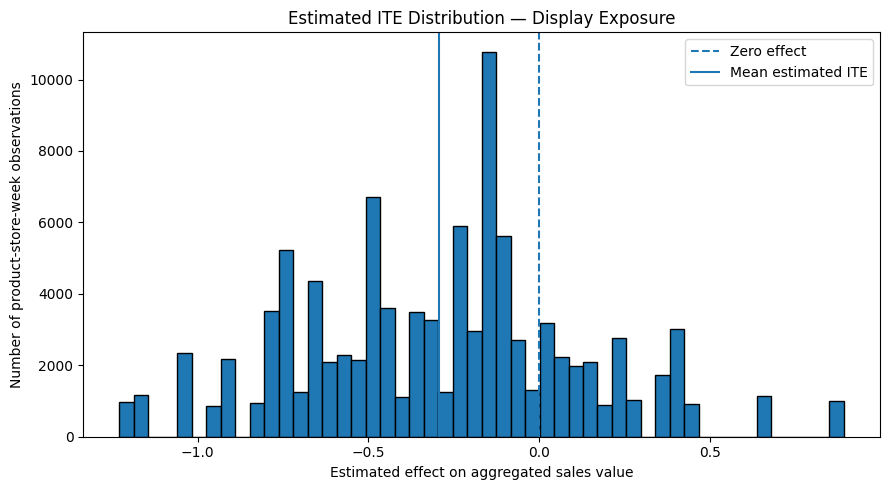

In [24]:
#ITE distribution
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("outputs") / "model_training"
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
plt.hist(
    ite_results["estimated_display_effect"],
    bins=50,
    edgecolor="black"
)
plt.axvline(0, linestyle="--", linewidth=1.5, label="Zero effect")
plt.axvline(
    ite_results["estimated_display_effect"].mean(),
    linestyle="-",
    linewidth=1.5,
    label="Mean estimated ITE"
)

plt.xlabel("Estimated effect on aggregated sales value")
plt.ylabel("Number of product-store-week observations")
plt.title("Estimated ITE Distribution — Display Exposure")
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "ite_distribution.png",
    dpi=150
)
plt.show()

In [25]:
import json

summary_data = {
    "project": "EconoCausal",
    "day": 1,
    "model": "EconML CausalForestDML",
    "nuisance_estimators": "Random Forest",
    "treatment": "display_exposed",
    "outcome": "SALES_VALUE",
    "modeling_unit": "product-store-week",
    "sample_size": int(len(ite_results)),
    "treatment_off": int((T_sample == 0).sum()),
    "treatment_on": int((T_sample == 1).sum()),
    "ite_mean": float(ite_results["estimated_display_effect"].mean()),
    "ite_std": float(ite_results["estimated_display_effect"].std()),
    "ite_min": float(ite_results["estimated_display_effect"].min()),
    "ite_median": float(ite_results["estimated_display_effect"].median()),
    "ite_max": float(ite_results["estimated_display_effect"].max()),
    "interpretation": (
        "Exploratory estimates only; further confounding control "
        "and validation are required before causal conclusions."
    )
}

with open(output_dir / "day1_model_summary.json", "w") as f:
    json.dump(summary_data, f, indent=4)

print("Saved model summary.")
print(output_dir.resolve())

Saved model summary.
/kaggle/working/outputs/model_training


In [26]:
#Train a second model for mailer promotions
import os
import json
import numpy as np
import pandas as pd

from econml.dml import CausalForestDML
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

# Output directory inside the GitHub repository
output_dir = "../outputs/model_training"
os.makedirs(output_dir, exist_ok=True)

# Use your existing aggregated and merged DataFrame
df = model_data.copy()

# Check required columns
required_columns = [
    "SALES_VALUE",
    "PRODUCT_ID",
    "STORE_ID",
    "WEEK_NO",
    "mailer_exposed",
    "display_exposed"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Treatment: whether the product-store-week had mailer exposure
T = df["mailer_exposed"].astype(int)

# Outcome: sales revenue
Y = df["SALES_VALUE"].astype(float)

# Control features
X = df[[
    "PRODUCT_ID",
    "STORE_ID",
    "WEEK_NO",
    "display_exposed"
]].astype(float)

# Keep valid observations
valid = (
    Y.notna()
    & T.notna()
    & X.notna().all(axis=1)
    & np.isfinite(Y)
    & np.isfinite(X).all(axis=1)
)

X = X.loc[valid]
Y = Y.loc[valid]
T = T.loc[valid]

print("Training rows:", len(Y))
print("Mailer treatment counts:")
print(T.value_counts().sort_index())

if T.nunique() != 2:
    raise ValueError(
        "Mailer treatment must contain both 0 and 1."
    )

# Keep training manageable initially
sample_size = min(100_000, len(Y))

sample = np.random.default_rng(42).choice(
    len(Y), size=sample_size, replace=False
)

X_sample = X.iloc[sample]
Y_sample = Y.iloc[sample]
T_sample = T.iloc[sample]

# Train Causal Forest DML
model = CausalForestDML(
    model_y=RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=10,
        n_jobs=-1,
        random_state=42
    ),
    model_t=RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        n_jobs=-1,
        random_state=42
    ),
    discrete_treatment=True,
    n_estimators=200,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

model.fit(
    Y_sample.to_numpy(),
    T_sample.to_numpy(),
    X=X_sample.to_numpy()
)

# Estimate individual treatment effects
ite = model.effect(X_sample.to_numpy())

results = pd.DataFrame({
    "PRODUCT_ID": df.loc[X_sample.index, "PRODUCT_ID"].to_numpy(),
    "STORE_ID": df.loc[X_sample.index, "STORE_ID"].to_numpy(),
    "WEEK_NO": df.loc[X_sample.index, "WEEK_NO"].to_numpy(),
    "mailer_exposed": T_sample.to_numpy(),
    "estimated_mailer_ite": np.asarray(ite).ravel()
})

results.to_csv(
    os.path.join(output_dir, "day2_mailer_ite_estimates.csv"),
    index=False
)

# Summary statistics
summary = results["estimated_mailer_ite"].describe()
summary.to_csv(
    os.path.join(output_dir, "day2_mailer_ite_summary.csv"),
    header=["value"]
)

print("\nMailer ITE summary:")
print(summary)

Training rows: 483320
Mailer treatment counts:
mailer_exposed
0    133132
1    350188
Name: count, dtype: int64

Mailer ITE summary:
count    100000.000000
mean         -0.072170
std           0.365496
min          -4.234475
25%          -0.276307
50%          -0.064240
75%           0.141600
max           4.461781
Name: estimated_mailer_ite, dtype: float64


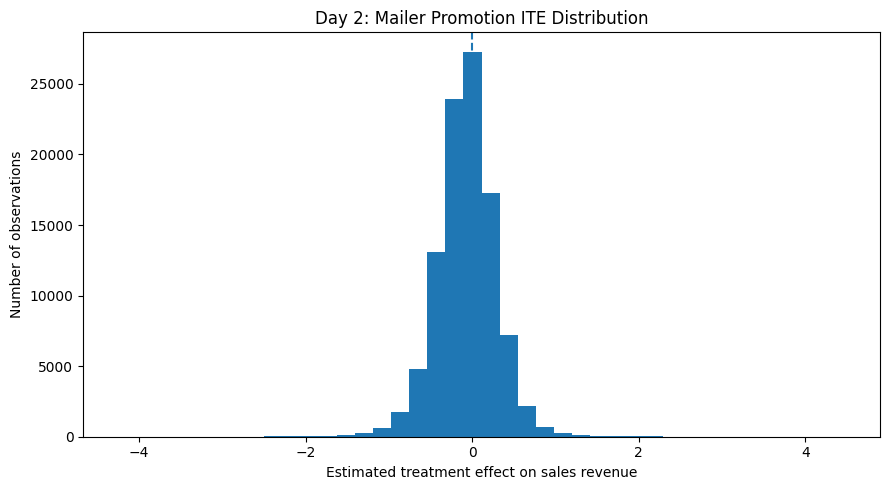

In [27]:
#Visualize the estimated effects
import matplotlib.pyplot as plt

effects = results["estimated_mailer_ite"]

plt.figure(figsize=(9, 5))
plt.hist(effects, bins=40)
plt.axvline(0, linestyle="--")
plt.xlabel("Estimated treatment effect on sales revenue")
plt.ylabel("Number of observations")
plt.title("Day 2: Mailer Promotion ITE Distribution")
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "day2_mailer_ite_distribution.png"),
    dpi=150
)

plt.show()

In [28]:
import os

print("Current notebook directory:")
print(os.getcwd())

print("\nOutput directory:")
print(os.path.abspath(output_dir))

print("\nFiles in output directory:")
print(os.listdir(output_dir))

Current notebook directory:
/kaggle/working

Output directory:
/kaggle/outputs/model_training

Files in output directory:
['day2_mailer_ite_estimates.csv', 'day2_mailer_ite_summary.csv', 'day2_mailer_ite_distribution.png']


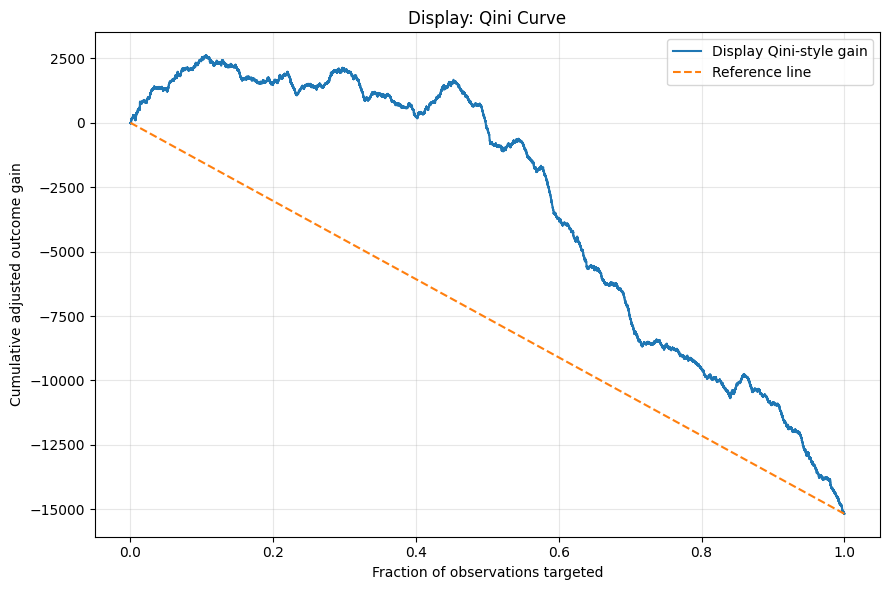


Display
Observations: 100000
Treated: 49123
Control: 50877
Curve CSV: /kaggle/working/outputs/model_training/display_qini_curve.csv
Curve image: /kaggle/working/outputs/model_training/display_qini_curve.png
Exploratory curve area: -0.031772094503946094
Cannot calculate Mailer Qini curve. Missing columns: ['SALES_VALUE']


In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
OUTPUT_DIR = Path("outputs") / "model_training"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def plot_qini_curve(
    df,
    treatment_col,
    outcome_col,
    effect_col,
    promotion_name,
    output_dir
):
    """
    Create a cumulative Qini-style gain curve by ranking observations
    by estimated treatment effect.

    The outcome must be observed for both treatment groups.
    """

    required = [treatment_col, outcome_col, effect_col]
    missing = [col for col in required if col not in df.columns]

    if missing:
        print(
            f"Cannot calculate {promotion_name} Qini curve. "
            f"Missing columns: {missing}"
        )
        return None

    data = df[required].copy()

    for col in required:
        data[col] = pd.to_numeric(data[col], errors="coerce")

    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    # Keep only binary treatment observations
    data = data[data[treatment_col].isin([0, 1])].copy()

    treated_count = (data[treatment_col] == 1).sum()
    control_count = (data[treatment_col] == 0).sum()

    if treated_count == 0 or control_count == 0:
        print(f"{promotion_name}: both treatment groups are required.")
        return None

    # Rank people/product-store-week records by predicted effect
    data = data.sort_values(
        effect_col, ascending=False
    ).reset_index(drop=True)

    treatment = data[treatment_col].to_numpy()
    outcome = data[outcome_col].to_numpy()

    # Cumulative outcome in each group
    treated_gain = np.cumsum((treatment == 1) * outcome)
    control_gain = np.cumsum((treatment == 0) * outcome)

    # Adjust control outcomes for the treatment/control group ratio
    qini_gain = (
        treated_gain
        - control_gain * (treated_count / control_count)
    )

    fraction_targeted = (
        np.arange(1, len(data) + 1) / len(data)
    )

    # Save the curve points
    curve_data = pd.DataFrame({
        "fraction_targeted": fraction_targeted,
        "qini_gain": qini_gain
    })

    safe_name = promotion_name.lower().replace(" ", "_")
    csv_path = output_dir / f"{safe_name}_qini_curve.csv"
    png_path = output_dir / f"{safe_name}_qini_curve.png"

    curve_data.to_csv(csv_path, index=False)

    # Plot curve
    plt.figure(figsize=(9, 6))
    plt.plot(
        np.r_[0, fraction_targeted],
        np.r_[0, qini_gain],
        label=f"{promotion_name} Qini-style gain"
    )
    plt.plot(
        [0, 1],
        [0, qini_gain[-1]],
        linestyle="--",
        label="Reference line"
    )

    plt.xlabel("Fraction of observations targeted")
    plt.ylabel("Cumulative adjusted outcome gain")
    plt.title(f"{promotion_name}: Qini Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(png_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

    # Approximate normalized area relative to the reference line
    area = np.trapezoid(
        np.r_[0, qini_gain] / max(len(data), 1),
        np.r_[0, fraction_targeted]
    )

    print(f"\n{promotion_name}")
    print("Observations:", len(data))
    print("Treated:", treated_count)
    print("Control:", control_count)
    print("Curve CSV:", csv_path.resolve())
    print("Curve image:", png_path.resolve())
    print("Exploratory curve area:", area)

    return curve_data


# ---------------------------------------------------
# 1. Display promotion
# ---------------------------------------------------
display_df = ite_results.copy()

display_curve = plot_qini_curve(
    df=display_df,
    treatment_col="display_exposed",
    outcome_col="SALES_VALUE",
    effect_col="estimated_display_effect",
    promotion_name="Display",
    output_dir=OUTPUT_DIR
)


# ---------------------------------------------------
# 2. Mailer promotion
# ---------------------------------------------------
# `results` is created by your mailer model cell.
# It currently has treatment and estimated ITE, but
# does not save SALES_VALUE in the notebook you shared.

if "results" in globals():
    mailer_df = results.copy()

    mailer_curve = plot_qini_curve(
        df=mailer_df,
        treatment_col="mailer_exposed",
        outcome_col="SALES_VALUE",
        effect_col="estimated_mailer_ite",
        promotion_name="Mailer",
        output_dir=OUTPUT_DIR
    )
else:
    print(
        "\nMailer curve skipped: run the mailer model cell first."
    )


In [30]:
from pathlib import Path

OUTPUT_DIR = Path("outputs") / "model_training"

print("Saved output files:")
for file in OUTPUT_DIR.glob("*qini*"):
    print(file.name)

Saved output files:
display_qini_curve.png
display_qini_curve.csv


In [31]:
print("Mailer results columns:")
if "results" in globals():
    print(results.columns.tolist())
else:
    print("The variable 'results' does not exist.")

print("\nITE-related CSV files:")
from pathlib import Path

for p in Path("outputs/model_training").glob("*ite*.csv"):
    print(p)

Mailer results columns:
['PRODUCT_ID', 'STORE_ID', 'WEEK_NO', 'mailer_exposed', 'estimated_mailer_ite']

ITE-related CSV files:
outputs/model_training/day1_ite_summary.csv
outputs/model_training/day1_ite_estimates.csv


In [33]:
print("Available data variables:")
print([name for name in globals() if name.lower() in
       ["transactions", "promotions", "model_data"]])

if "transactions" in globals():
    print("\nTransactions columns:")
    print(transactions.columns.tolist())
    display(transactions.head())

Available data variables:
['transactions', 'promotions', 'model_data']

Transactions columns:
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC']


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


In [34]:
# Keep the identifiers and actual outcome from transaction data
outcome_data = transactions[
    ["PRODUCT_ID", "STORE_ID", "WEEK_NO", "SALES_VALUE"]
].copy()

# Aggregate first in case multiple rows share the same keys
outcome_data = outcome_data.groupby(
    ["PRODUCT_ID", "STORE_ID", "WEEK_NO"],
    as_index=False
)["SALES_VALUE"].sum()

# Attach actual sales to mailer ITE predictions
mailer_df = results.merge(
    outcome_data,
    on=["PRODUCT_ID", "STORE_ID", "WEEK_NO"],
    how="left",
    validate="many_to_one"
)

print("Mailer rows:", len(mailer_df))
print("Rows with missing sales:", mailer_df["SALES_VALUE"].isna().sum())
display(mailer_df.head())

Mailer rows: 100000
Rows with missing sales: 0


,PRODUCT_ID,STORE_ID,WEEK_NO,mailer_exposed,estimated_mailer_ite,SALES_VALUE
0,965766,400,29,1,-0.116563,1.67
1,894425,367,12,1,0.284820,5.80
2,939578,292,90,1,-0.273088,2.25
3,909894,319,39,1,0.245077,1.00
4,1002558,367,73,1,-0.346661,2.90


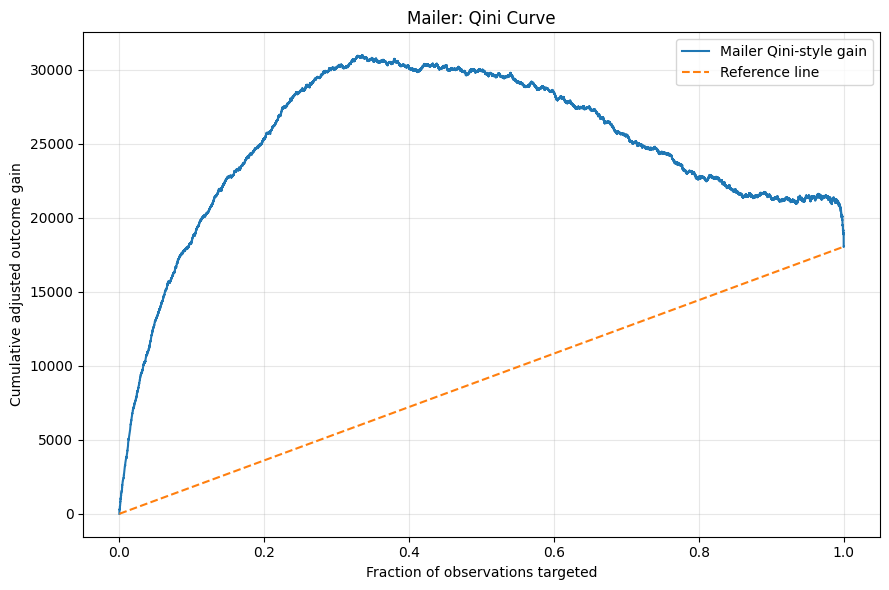


Mailer
Observations: 100000
Treated: 72469
Control: 27531
Curve CSV: /kaggle/working/outputs/model_training/mailer_qini_curve.csv
Curve image: /kaggle/working/outputs/model_training/mailer_qini_curve.png
Exploratory curve area: 0.24687557762923065


In [35]:
mailer_curve = plot_qini_curve(
    df=mailer_df,
    treatment_col="mailer_exposed",
    outcome_col="SALES_VALUE",
    effect_col="estimated_mailer_ite",
    promotion_name="Mailer",
    output_dir=OUTPUT_DIR
)

In [36]:
from pathlib import Path

OUTPUT_DIR = Path("outputs") / "model_training"

print("Qini curve output files:")
for file in OUTPUT_DIR.glob("*qini*"):
    print(file.name)

Qini curve output files:
mailer_qini_curve.png
mailer_qini_curve.csv
display_qini_curve.png
display_qini_curve.csv


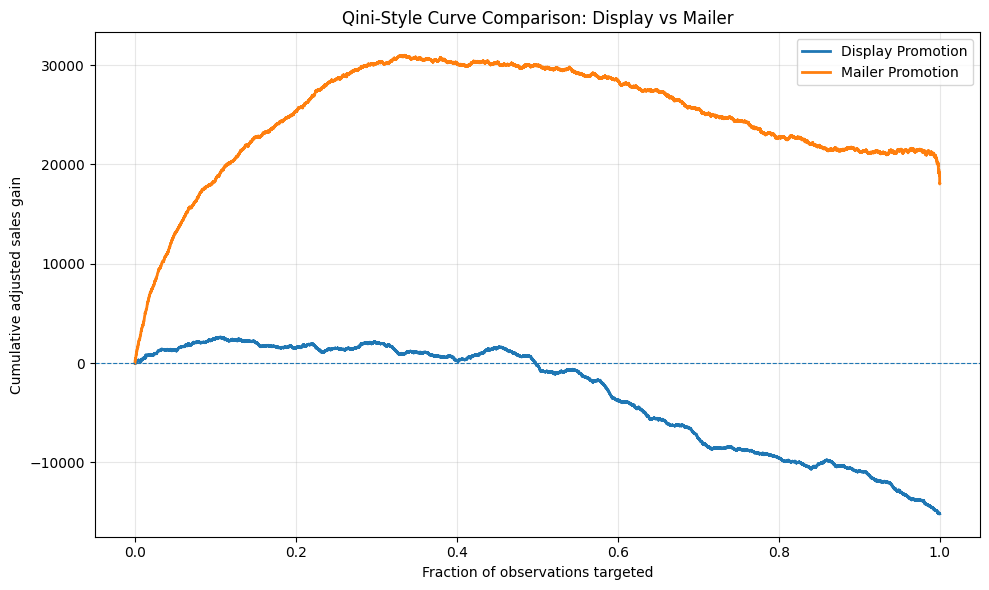

Comparison plot saved to: /kaggle/working/outputs/model_training/display_vs_mailer_qini.png


In [37]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

OUTPUT_DIR = Path("outputs") / "model_training"

# Load saved curve data
display_curve = pd.read_csv(
    OUTPUT_DIR / "display_qini_curve.csv"
)
mailer_curve = pd.read_csv(
    OUTPUT_DIR / "mailer_qini_curve.csv"
)

# Plot both curves
plt.figure(figsize=(10, 6))

plt.plot(
    np.r_[0, display_curve["fraction_targeted"]],
    np.r_[0, display_curve["qini_gain"]],
    label="Display Promotion",
    linewidth=2
)

plt.plot(
    np.r_[0, mailer_curve["fraction_targeted"]],
    np.r_[0, mailer_curve["qini_gain"]],
    label="Mailer Promotion",
    linewidth=2
)

plt.axhline(0, linestyle="--", linewidth=0.8)
plt.xlabel("Fraction of observations targeted")
plt.ylabel("Cumulative adjusted sales gain")
plt.title("Qini-Style Curve Comparison: Display vs Mailer")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

comparison_path = OUTPUT_DIR / "display_vs_mailer_qini.png"
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()

print("Comparison plot saved to:", comparison_path.resolve())
